# 3.2 Pixels + similarité cosinus : Dataset 1

Sans OCR. Chaque image devient un vecteur, puis prend la classe du centroïde le plus proche au sens du
cosinus (`classify_by_cosine` de [outils_3.py](outils_3.py)).

| Représentation | Vecteur |
|---|---|
| `raw` | l'image en 64x64 |
| `centered` | `raw` moins l'image moyenne du train |
| `profiles` | l'encre par ligne et par colonne |
| `hog` | l'orientation des contours |
| `shape` | le format et la densité d'encre |

La marge, c'est la ressemblance à sa propre classe moins la ressemblance aux autres.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from skimage.feature import hog
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from tqdm import tqdm

from outils_3 import list_images, classify_by_cosine

DOSSIER = "../data/document-classification-dataset_1"

## 1. Calcul des représentations

In [2]:
df = list_images(DOSSIER)
y = df["label"].values

raw, profils, hogs, formes = [], [], [], []
for chemin in tqdm(df["filepath"]):
    image = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)
    hauteur, largeur = image.shape
    # otsu : 1 = encre, 0 = fond
    _, encre = cv2.threshold(image, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # mise à plat
    raw.append(cv2.resize(image, (64, 64), interpolation=cv2.INTER_AREA).ravel() / 255)

    # quantité d'encre par ligne et par colonne
    grille = np.linspace(0, 1, 256)
    par_ligne = np.interp(grille, np.linspace(0, 1, hauteur), encre.mean(axis=1))
    par_colonne = np.interp(grille, np.linspace(0, 1, largeur), encre.mean(axis=0))
    profils.append(np.concatenate([par_ligne, par_colonne]))

    # hog : orientation des contours
    hogs.append(hog(cv2.resize(image, (128, 128), interpolation=cv2.INTER_AREA),
                    orientations=9, pixels_per_cell=(16, 16), cells_per_block=(3, 3)))

    # le format et la quantité d'encre
    formes.append([hauteur / largeur, encre.mean()])

# on découpe les numéros de ligne, pas les images
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, random_state=1, stratify=y)

raw = np.array(raw)
representations = {
    "raw": raw,
    "centered": raw - raw[idx_train].mean(axis=0),  # moyenne du train seulement
    "profiles": np.array(profils),
    "hog": np.array(hogs),
    "shape": np.array(formes),
}
for nom, X in representations.items():
    print(f"{nom:9s} : {X.shape[1]} valeurs par image")

  0%|          | 0/165 [00:00<?, ?it/s]

  5%|▌         | 9/165 [00:00<00:01, 89.04it/s]

 12%|█▏        | 20/165 [00:00<00:01, 97.16it/s]

 19%|█▉        | 31/165 [00:00<00:01, 99.76it/s]

 25%|██▌       | 42/165 [00:00<00:01, 100.89it/s]

...

 84%|████████▍ | 139/165 [00:01<00:00, 105.29it/s]

 92%|█████████▏| 151/165 [00:01<00:00, 106.97it/s]

 99%|█████████▉| 163/165 [00:01<00:00, 108.99it/s]

100%|██████████| 165/165 [00:01<00:00, 102.86it/s]

raw       : 4096 valeurs par image
centered  : 4096 valeurs par image
profiles  : 512 valeurs par image
hog       : 2916 valeurs par image
shape     : 2 valeurs par image


## 2. Centroïdes + cosinus pour chaque représentation

In [3]:
lignes, predictions = [], {}
for nom, X in representations.items():
    predictions[nom], similarites = classify_by_cosine(X[idx_train], y[idx_train], X[idx_test])

    # marge = ressemblance à sa propre classe - ressemblance aux autres
    est_vraie_classe = np.array([similarites.columns == vrai for vrai in y[idx_test]])
    intra = similarites.values[est_vraie_classe].mean()
    inter = similarites.values[~est_vraie_classe].mean()

    lignes.append({"représentation": nom, "accuracy": accuracy_score(y[idx_test], predictions[nom]),
                   "sim_intra": intra, "sim_inter": inter, "marge": intra - inter})

tableau = pd.DataFrame(lignes).sort_values("marge", ascending=False).reset_index(drop=True)
tableau.round(4)

,représentation,accuracy,sim_intra,sim_inter,marge
0,centered,0.6970,0.3713,-0.2235,0.5948
1,hog,0.9091,0.8133,0.6711,0.1422
2,profiles,0.8182,0.6415,0.5430,0.0985
3,shape,0.6667,0.9997,0.9985,0.0012
4,raw,0.7879,0.9946,0.9939,0.0008


`raw` : plus de 0,99 de similarité partout. Toutes les pages ressemblent à une page blanche, la
marge est presque nulle.

## 3. Marge de séparation par représentation

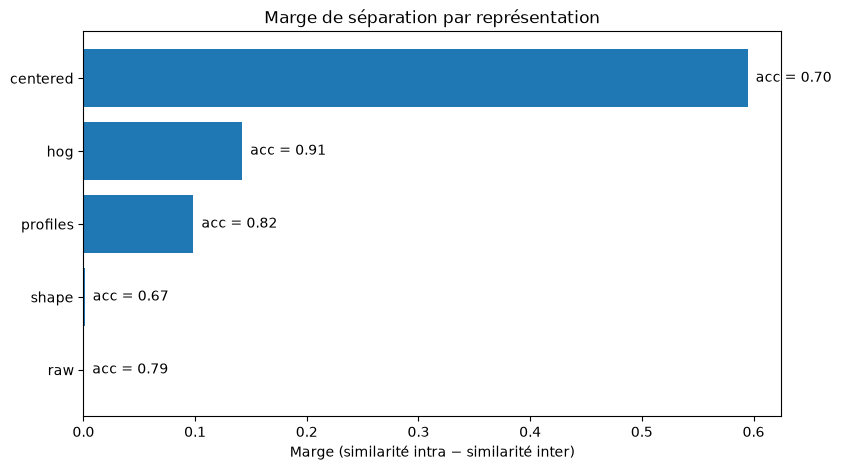

In [4]:
plt.figure(figsize=(9, 5))
plt.barh(tableau["représentation"], tableau["marge"])
for i, (marge, acc) in enumerate(zip(tableau["marge"], tableau["accuracy"])):
    plt.text(marge, i, f"  acc = {acc:.2f}", va="center")
plt.gca().invert_yaxis()
plt.xlabel("Marge (similarité intra − similarité inter)")
plt.title("Marge de séparation par représentation")
plt.show()

## 4. Matrice de confusion de la représentation à la plus grande marge

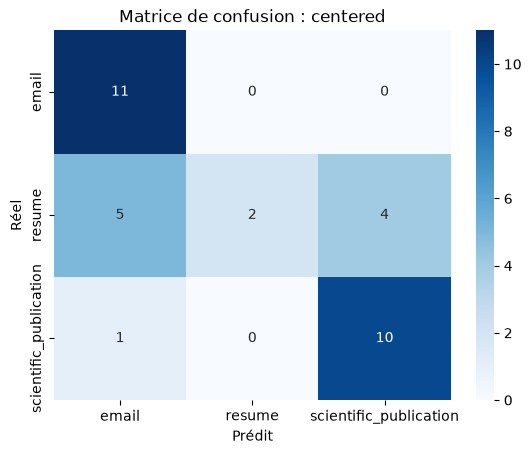

In [5]:
meilleure = tableau.loc[0, "représentation"]
matrice = pd.crosstab(y[idx_test], predictions[meilleure], rownames=["Réel"], colnames=["Prédit"])
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues")
plt.title(f"Matrice de confusion : {meilleure}")
plt.show()